In [2]:
# Run once in Colab. TensorFlow and the scientific Python stack are already included there.
%pip install -q wfdb iterative-stratification kagglehub


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 14.6 MB/s eta 0:00:00


In [3]:
import os
import re
import gc
import json
import math
import random
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from scipy.signal import butter, sosfiltfilt, iirnotch, tf2sos, resample_poly
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, hamming_loss,
    multilabel_confusion_matrix, roc_curve, precision_recall_curve,
)
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from tqdm.auto import tqdm
import wfdb

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow:", tf.__version__)
print("GPU(s):", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
class Config:

    DATA_PATH = Path(os.environ.get("CPSC2018_PATH", "/content/cpsc2018"))
    RECORD_GLOB = "A*.hea" 
    AUTO_DOWNLOAD_FROM_KAGGLE = True

    WORK_DIR = Path(os.environ.get("CPSC2018_WORK_DIR", "/content/CPSC2018_work"))
    PROCESSED_SIGNAL_PATH = WORK_DIR / "cpsc2018_filtered_100hz_10s.npy"
    PROCESSED_INDEX_PATH = WORK_DIR / "cpsc2018_filtered_index.csv"

    SOURCE_SAMPLING_RATE = 500
    SAMPLING_RATE = 500
    SIGNAL_DURATION_SEC = 10
    SIGNAL_LENGTH = SAMPLING_RATE * SIGNAL_DURATION_SEC

    NUM_LEADS = 12
    LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF",
                  "V1", "V2", "V3", "V4", "V5", "V6"]

    BANDPASS_LOW = 0.5
    BANDPASS_HIGH = 40.0
    BANDPASS_ORDER = 4
    NOTCH_FREQS = [50.0]
    NOTCH_Q = 30.0

    TRAIN_SIZE = 0.80
    VAL_SIZE = 0.10
    TEST_SIZE = 0.10

    AUG_PROB = 0.5
    AUG_GAUSSIAN_NOISE_STD = 0.05
    AUG_AMPLITUDE_SCALE_RANGE = (0.9, 1.1)
    AUG_TIME_SHIFT_MAX = 100
    AUG_LEAD_DROPOUT_PROB = 0.2
    AUG_LEAD_DROPOUT_MAX_LEADS = 2

    BATCH_SIZE = 32
    EPOCHS = 60
    CLASS_WEIGHT_MIN = 0.5
    CLASS_WEIGHT_MAX = 10.0
    USE_WEIGHTED_BCE = False  

    REBUILD_PREPROCESSED = False
    BEST_MODEL_PATH = WORK_DIR / "best_cpsc2018_model.keras"
    FINAL_MODEL_PATH = WORK_DIR / "final_cpsc2018_model.keras"


cfg = Config()
cfg.WORK_DIR.mkdir(parents=True, exist_ok=True)

assert math.isclose(cfg.TRAIN_SIZE + cfg.VAL_SIZE + cfg.TEST_SIZE, 1.0)
assert cfg.SIGNAL_LENGTH == 5000, 

print("=" * 68)
print("CPSC2018 multilabel pipeline")
print("=" * 68)
print("Data path       :", cfg.DATA_PATH)
print("Work path       :", cfg.WORK_DIR)
print("Source rate     :", cfg.SOURCE_SAMPLING_RATE, "Hz")
print("Model input rate:", cfg.SAMPLING_RATE, "Hz")
print("Model input     :", (cfg.SIGNAL_LENGTH, cfg.NUM_LEADS))


CPSC2018 multilabel pipeline
Data path       : /content/cpsc2018
Work path       : /content/CPSC2018_work
Source rate     : 500 Hz
Model input rate: 500 Hz
Model input     : (5000, 12)


In [ ]:
# Data acquisition options:

if cfg.AUTO_DOWNLOAD_FROM_KAGGLE:
    import kagglehub
    cfg.DATA_PATH = Path(
        kagglehub.dataset_download(
            "physionet/china-physiological-signal-challenge-in-2018"
        )
    )
    print("Downloaded CPSC2018 to:", cfg.DATA_PATH)
else:
    print("Using configured CPSC2018 path:", cfg.DATA_PATH)


100%|██████████| 824M/824M [00:44<00:00, 19.3MB/s]

Extracting files...


Downloaded CPSC2018 to: /root/.cache/kagglehub/datasets/physionet/china-physiological-signal-challenge-in-2018/versions/1


In [ ]:
CLASSES = ["NORM", "AF", "I-AVB", "LBBB", "RBBB", "PAC", "PVC", "STD", "STE"]

CPSC_NUMERIC_TO_CLASS = {
    "1": "NORM", "2": "AF", "3": "I-AVB", "4": "LBBB", "5": "RBBB",
    "6": "PAC", "7": "PVC", "8": "STD", "9": "STE",
}

SNOMED_TO_CLASS = {
    "426783006": "NORM",
    "164889003": "AF",
    "270492004": "I-AVB",
    "164909002": "LBBB",
    "59118001": "RBBB",
    "284470004": "PAC",
    "164884008": "PVC",
    "429622005": "STD",
    "164931005": "STE",
}

NAME_TO_CLASS = {
    "normal": "NORM", "normal rhythm": "NORM", "norm": "NORM", "n": "NORM",
    "af": "AF", "atrial fibrillation": "AF",
    "i-avb": "I-AVB", "iavb": "I-AVB", "1avb": "I-AVB",
    "first degree av block": "I-AVB",
    "lbbb": "LBBB", "rbbb": "RBBB", "pac": "PAC", "pvc": "PVC",
    "std": "STD", "st depression": "STD", "ste": "STE", "st elevation": "STE",
}


def canonical_label(token):
    token = str(token).strip().strip("'\"[](){}")
    if re.fullmatch(r"\d+\.0", token):
        token = token[:-2]
    if token in CPSC_NUMERIC_TO_CLASS:
        return CPSC_NUMERIC_TO_CLASS[token]
    if token in SNOMED_TO_CLASS:
        return SNOMED_TO_CLASS[token]
    return NAME_TO_CLASS.get(token.lower())


def parse_reference_files(data_path):
    lookup = {}
    for csv_path in sorted(Path(data_path).rglob("REFERENCE.csv")):
        ref = pd.read_csv(csv_path, header=None, dtype=str, keep_default_na=False)
        for row in ref.itertuples(index=False, name=None):
            if not row:
                continue
            record_id = Path(str(row[0]).strip()).stem
            labels = set()
            for cell in row[1:]:
                for token in re.split(r"[,;|\s]+", str(cell).strip()):
                    if token:
                        label = canonical_label(token)
                        if label:
                            labels.add(label)
            if labels:
                lookup.setdefault(record_id, set()).update(labels)
    return lookup


def parse_header(hea_path):
    lines = Path(hea_path).read_text(errors="ignore").splitlines()
    if not lines:
        raise ValueError(f"Empty header: {hea_path}")

    first = lines[0].split()
    record_id = first[0]
    fs = float(first[2])
    n_samples = int(first[3])

    comments = {}
    for line in lines:
        if line.startswith("#") and ":" in line:
            key, value = line[1:].split(":", 1)
            comments[key.strip().lower()] = value.strip()

    age_text = comments.get("age", "")
    try:
        age = float(age_text)
    except (TypeError, ValueError):
        age = np.nan

    sex_text = comments.get("sex", "").strip().lower()
    sex = 1.0 if sex_text in {"male", "m"} else 0.0 if sex_text in {"female", "f"} else np.nan

    dx_tokens = [t.strip() for t in re.split(r"[,;|]", comments.get("dx", "")) if t.strip()]
    return {
        "record_id": record_id,
        "fs": fs,
        "n_samples": n_samples,
        "age": age,
        "sex": sex,
        "dx_tokens": dx_tokens,
    }


In [7]:
def discover_cpsc2018_records(data_path):
    data_path = Path(data_path)
    if not data_path.exists():
        raise FileNotFoundError(
            f"CPSC2018 DATA_PATH does not exist: {data_path}\n"
            "Set cfg.DATA_PATH to the extracted WFDB-format CPSC2018 folder."
        )

    reference_lookup = parse_reference_files(data_path)
    hea_files = sorted(data_path.rglob(cfg.RECORD_GLOB))
    if not hea_files:
        raise FileNotFoundError(
            f"No {cfg.RECORD_GLOB} files found below {data_path}. "
            "Use the WFDB-format release with paired .hea/.mat files."
        )

    rows = []
    unknown_dx = Counter()
    missing_label = []
    missing_signal = []

    for hea_path in tqdm(hea_files, desc="Reading CPSC2018 headers"):
        info = parse_header(hea_path)
        record_id = info["record_id"]
        mat_path = hea_path.with_suffix(".mat")
        if not mat_path.exists():
            missing_signal.append(record_id)
            continue

        labels = set()
        for token in info["dx_tokens"]:
            label = canonical_label(token)
            if label:
                labels.add(label)
            else:
                unknown_dx[token] += 1
        labels.update(reference_lookup.get(record_id, set()))

        if not labels:
            missing_label.append(record_id)
            continue

        ordered_labels = tuple(c for c in CLASSES if c in labels)
        rows.append({
            "record_id": record_id,
            "hea_path": str(hea_path),
            "mat_path": str(mat_path),
            "source_fs": info["fs"],
            "source_samples": info["n_samples"],
            "duration_sec": info["n_samples"] / info["fs"],
            "age": info["age"],
            "sex": info["sex"],
            "labels": ordered_labels,
        })

    if not rows:
        raise ValueError(
            "No labeled CPSC2018 records were discovered. Check DATA_PATH and label files."
        )
    df = pd.DataFrame(rows).sort_values("record_id").reset_index(drop=True)
    before_demographics = len(df)
    df = df[df["age"].notna() & df["sex"].notna()].reset_index(drop=True)

    if df["record_id"].duplicated().any():
        duplicates = df.loc[df["record_id"].duplicated(), "record_id"].tolist()
        raise ValueError(f"Duplicate record IDs detected: {duplicates[:10]}")

    print(f"Headers found                  : {len(hea_files):,}")
    print(f"Usable labeled records         : {before_demographics:,}")
    print(f"After missing age/sex removal  : {len(df):,}")
    print(f"Missing paired .mat files      : {len(missing_signal):,}")
    print(f"Records without target labels  : {len(missing_label):,}")
    if unknown_dx:
        print("Ignored non-target/unknown diagnosis codes:", dict(unknown_dx.most_common(10)))

    if len(df) == 0:
        raise ValueError("No usable CPSC2018 records remained after validation.")
    return df


df_meta = discover_cpsc2018_records(cfg.DATA_PATH)
display(df_meta.head())

label_counts = Counter(label for labels in df_meta["labels"] for label in labels)
print("\nClass counts:", {c: label_counts[c] for c in CLASSES})
print("Mean labels per record:", df_meta["labels"].apply(len).mean().round(3))
print("Records with >1 label:", int((df_meta["labels"].apply(len) > 1).sum()))


Reading CPSC2018 headers:   0%|          | 0/6877 [00:00<?, ?it/s]

Headers found                  : 6,877
Usable labeled records         : 6,877
After missing age/sex removal  : 6,872
Missing paired .mat files      : 0
Records without target labels  : 0


,record_id,hea_path,mat_path,source_fs,source_samples,duration_sec,age,sex,labels
0,A0001,/root/.cache/kagglehub/datasets/physionet/chin...,/root/.cache/kagglehub/datasets/physionet/chin...,500.0,7500,15.000,74.0,1.0,"(RBBB,)"
1,A0002,/root/.cache/kagglehub/datasets/physionet/chin...,/root/.cache/kagglehub/datasets/physionet/chin...,500.0,5000,10.000,49.0,0.0,"(NORM,)"
2,A0003,/root/.cache/kagglehub/datasets/physionet/chin...,/root/.cache/kagglehub/datasets/physionet/chin...,500.0,5000,10.000,81.0,0.0,"(AF,)"
3,A0004,/root/.cache/kagglehub/datasets/physionet/chin...,/root/.cache/kagglehub/datasets/physionet/chin...,500.0,5974,11.948,45.0,1.0,"(AF,)"
4,A0005,/root/.cache/kagglehub/datasets/physionet/chin...,/root/.cache/kagglehub/datasets/physionet/chin...,500.0,12500,25.000,53.0,1.0,"(PVC,)"



Class counts: {'NORM': 917, 'AF': 1221, 'I-AVB': 722, 'LBBB': 236, 'RBBB': 1854, 'PAC': 616, 'PVC': 700, 'STD': 868, 'STE': 220}
Mean labels per record: 1.07
Records with >1 label: 476


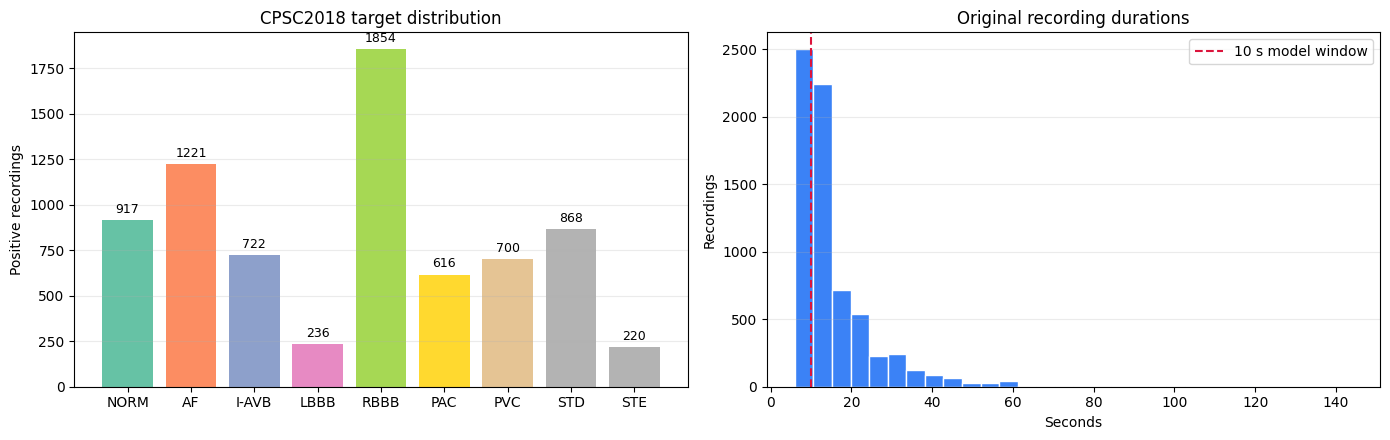

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

counts = np.array([label_counts[c] for c in CLASSES])
bars = axes[0].bar(CLASSES, counts, color=plt.cm.Set2(np.linspace(0, 1, len(CLASSES))))
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set_title("CPSC2018 target distribution")
axes[0].set_ylabel("Positive recordings")
axes[0].grid(axis="y", alpha=0.25)

axes[1].hist(df_meta["duration_sec"], bins=30, color="#3B82F6", edgecolor="white")
axes[1].axvline(cfg.SIGNAL_DURATION_SEC, color="crimson", linestyle="--", label="10 s model window")
axes[1].set_title("Original recording durations")
axes[1].set_xlabel("Seconds")
axes[1].set_ylabel("Recordings")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [9]:
def load_standard_12_lead_signal(hea_path):
    record_path = str(Path(hea_path).with_suffix(""))
    signal, fields = wfdb.rdsamp(record_path)
    signal = np.asarray(signal, dtype=np.float32)
    source_fs = float(fields["fs"])
    source_leads = list(fields["sig_name"])

    lead_to_index = {name: i for i, name in enumerate(source_leads)}
    missing = [lead for lead in cfg.LEAD_NAMES if lead not in lead_to_index]
    if missing:
        raise ValueError(f"{Path(hea_path).name} is missing standard leads: {missing}")

    signal = signal[:, [lead_to_index[lead] for lead in cfg.LEAD_NAMES]]
    signal = np.nan_to_num(signal, nan=0.0, posinf=0.0, neginf=0.0)
    return signal, source_fs


def filter_ecg(signal, fs):
    nyquist = fs / 2.0
    if not (0 < cfg.BANDPASS_LOW < cfg.BANDPASS_HIGH < nyquist):
        raise ValueError(f"Invalid bandpass {cfg.BANDPASS_LOW}-{cfg.BANDPASS_HIGH} Hz for fs={fs}")

    sos_bp = butter(
        cfg.BANDPASS_ORDER,
        [cfg.BANDPASS_LOW / nyquist, cfg.BANDPASS_HIGH / nyquist],
        btype="band",
        output="sos",
    )
    filtered = sosfiltfilt(sos_bp, signal, axis=0)

    for freq in cfg.NOTCH_FREQS:
        if 0 < freq < nyquist:
            notch_sos = tf2sos(*iirnotch(freq, cfg.NOTCH_Q, fs=fs))
            filtered = sosfiltfilt(notch_sos, filtered, axis=0)
    return filtered.astype(np.float32)


def resample_ecg(signal, source_fs, target_fs):
    source_fs_int = int(round(source_fs))
    target_fs_int = int(round(target_fs))
    divisor = math.gcd(source_fs_int, target_fs_int)
    up = target_fs_int // divisor
    down = source_fs_int // divisor
    return resample_poly(signal, up=up, down=down, axis=0).astype(np.float32)


def center_crop_or_pad(signal, target_length):
    n = signal.shape[0]
    if n >= target_length:
        start = (n - target_length) // 2
        return signal[start:start + target_length].astype(np.float32, copy=False)

    output = np.zeros((target_length, signal.shape[1]), dtype=np.float32)
    start = (target_length - n) // 2
    output[start:start + n] = signal
    return output


def preprocess_one_record(hea_path):
    signal, source_fs = load_standard_12_lead_signal(hea_path)
    signal = filter_ecg(signal, source_fs)
    signal = resample_ecg(signal, source_fs, cfg.SAMPLING_RATE)
    signal = center_crop_or_pad(signal, cfg.SIGNAL_LENGTH)
    if signal.shape != (cfg.SIGNAL_LENGTH, cfg.NUM_LEADS):
        raise AssertionError(f"Unexpected processed shape: {signal.shape}")
    return signal


In [10]:
def preprocessing_signature():
    return json.dumps({
        "sampling_rate": cfg.SAMPLING_RATE,
        "signal_length": cfg.SIGNAL_LENGTH,
        "lead_names": cfg.LEAD_NAMES,
        "bandpass_low": cfg.BANDPASS_LOW,
        "bandpass_high": cfg.BANDPASS_HIGH,
        "bandpass_order": cfg.BANDPASS_ORDER,
        "notch_freqs": cfg.NOTCH_FREQS,
        "notch_q": cfg.NOTCH_Q,
    }, sort_keys=True)


def cache_matches_metadata(index_path, df):
    if not index_path.exists():
        return False
    cached = pd.read_csv(index_path, dtype={"record_id": str})
    return (
        cached["record_id"].tolist() == df["record_id"].astype(str).tolist()
        and "preprocessing_signature" in cached
        and cached["preprocessing_signature"].nunique() == 1
        and cached["preprocessing_signature"].iloc[0] == preprocessing_signature()
    )


def build_or_load_preprocessed_signals(df):
    expected_shape = (len(df), cfg.SIGNAL_LENGTH, cfg.NUM_LEADS)
    can_reuse = (
        not cfg.REBUILD_PREPROCESSED
        and cfg.PROCESSED_SIGNAL_PATH.exists()
        and cache_matches_metadata(cfg.PROCESSED_INDEX_PATH, df)
    )

    if can_reuse:
        X = np.load(cfg.PROCESSED_SIGNAL_PATH, mmap_mode="r")
        if X.shape == expected_shape and X.dtype == np.float32:
            print("Loaded cached processed ECG array:", X.shape)
            return X
        print("Cache shape/dtype mismatch; rebuilding.")

    X = np.lib.format.open_memmap(
        cfg.PROCESSED_SIGNAL_PATH,
        mode="w+",
        dtype=np.float32,
        shape=expected_shape,
    )

    for i, hea_path in enumerate(tqdm(df["hea_path"], desc="Filter/resample/crop CPSC2018")):
        X[i] = preprocess_one_record(hea_path)
        if i % 250 == 0:
            X.flush()
            gc.collect()
    X.flush()

    pd.DataFrame({
        "record_id": df["record_id"].astype(str),
        "preprocessing_signature": preprocessing_signature(),
    }).to_csv(
        cfg.PROCESSED_INDEX_PATH, index=False
    )
    print("Saved processed ECG array:", cfg.PROCESSED_SIGNAL_PATH)
    return np.load(cfg.PROCESSED_SIGNAL_PATH, mmap_mode="r")


X_all = build_or_load_preprocessed_signals(df_meta)
assert X_all.shape == (len(df_meta), cfg.SIGNAL_LENGTH, cfg.NUM_LEADS)
assert np.isfinite(X_all[: min(32, len(X_all))]).all()
print("Processed ECG shape:", X_all.shape, "dtype:", X_all.dtype)


Filter/resample/crop CPSC2018:   0%|          | 0/6872 [00:00<?, ?it/s]

Saved processed ECG array: /content/CPSC2018_work/cpsc2018_filtered_100hz_10s.npy
Processed ECG shape: (6872, 5000, 12) dtype: float32


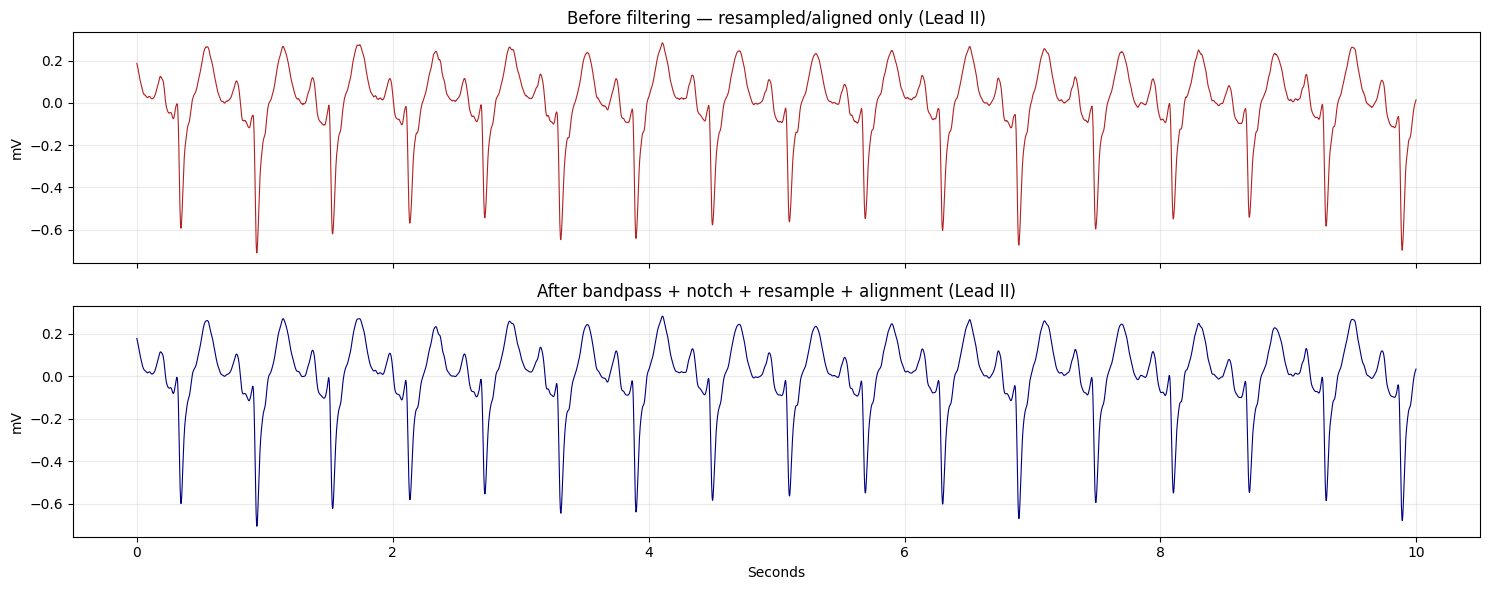

In [ ]:
sample_idx = 0
raw_signal, raw_fs = load_standard_12_lead_signal(df_meta.iloc[sample_idx]["hea_path"])
raw_100hz = center_crop_or_pad(
    resample_ecg(raw_signal, raw_fs, cfg.SAMPLING_RATE), cfg.SIGNAL_LENGTH
)
processed_signal = X_all[sample_idx]

t = np.arange(cfg.SIGNAL_LENGTH) / cfg.SAMPLING_RATE
lead_idx = 1 
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
axes[0].plot(t, raw_100hz[:, lead_idx], color="firebrick", linewidth=0.8)
axes[0].set_title("Before filtering — resampled/aligned only (Lead II)")
axes[1].plot(t, processed_signal[:, lead_idx], color="navy", linewidth=0.8)
axes[1].set_title("After bandpass + notch + resample + alignment (Lead II)")
for ax in axes:
    ax.set_ylabel("mV")
    ax.grid(alpha=0.25)
axes[1].set_xlabel("Seconds")
plt.tight_layout()
plt.show()


In [12]:
mlb = MultiLabelBinarizer(classes=CLASSES)
y_all = mlb.fit_transform(df_meta["labels"]).astype(np.float32)
classes = list(mlb.classes_)

splitter_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=cfg.VAL_SIZE + cfg.TEST_SIZE,
    random_state=SEED,
)
train_idx, temp_idx = next(splitter_1.split(np.zeros((len(y_all), 1)), y_all))

relative_test_size = cfg.TEST_SIZE / (cfg.VAL_SIZE + cfg.TEST_SIZE)
splitter_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=relative_test_size,
    random_state=SEED,
)
val_rel_idx, test_rel_idx = next(
    splitter_2.split(np.zeros((len(temp_idx), 1)), y_all[temp_idx])
)
val_idx = temp_idx[val_rel_idx]
test_idx = temp_idx[test_rel_idx]

split_indices = {
    "train": np.asarray(train_idx),
    "val": np.asarray(val_idx),
    "test": np.asarray(test_idx),
}

assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(df_meta)

X_train = np.asarray(X_all[train_idx], dtype=np.float32)
X_val = np.asarray(X_all[val_idx], dtype=np.float32)
X_test = np.asarray(X_all[test_idx], dtype=np.float32)
y_train = y_all[train_idx]
y_val = y_all[val_idx]
y_test = y_all[test_idx]

print("Classes:", classes)
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)


Classes: ['NORM', 'AF', 'I-AVB', 'LBBB', 'RBBB', 'PAC', 'PVC', 'STD', 'STE']
Train: (5496, 5000, 12) (5496, 9)
Val  : (689, 5000, 12) (689, 9)
Test : (687, 5000, 12) (687, 9)


[PASS] Splits are disjoint, exhaustive, and contain every class.


,train_n,val_n,test_n,train_%,val_%,test_%
NORM,734,92,91,13.360000,13.350000,13.25
AF,977,122,122,17.780001,17.709999,17.76
I-AVB,578,72,72,10.520000,10.450000,10.48
LBBB,189,23,24,3.440000,3.340000,3.49
RBBB,1483,185,186,26.980000,26.850000,27.07
PAC,493,61,62,8.970000,8.850000,9.02
PVC,560,70,70,10.190000,10.160000,10.19
STD,694,87,87,12.630000,12.630000,12.66
STE,176,22,22,3.200000,3.190000,3.20


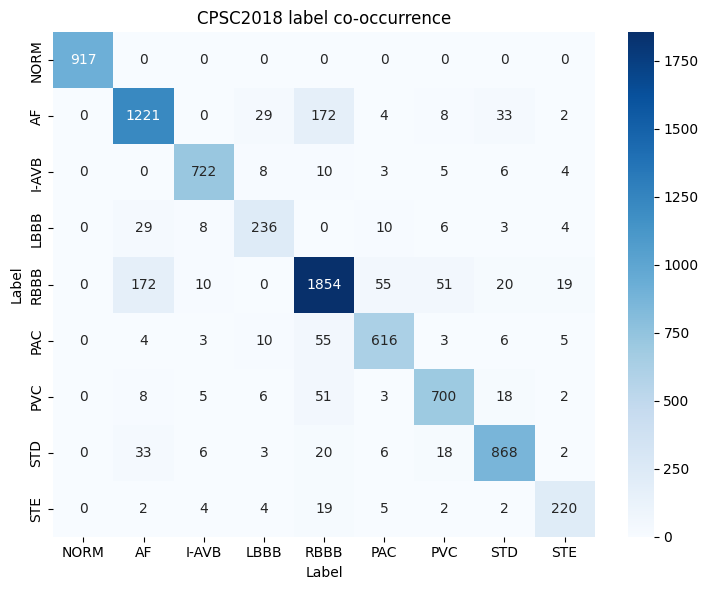

In [13]:
def verify_splits(y_train, y_val, y_test, class_names):
    dist = pd.DataFrame(
        {
            "train_n": y_train.sum(axis=0).astype(int),
            "val_n": y_val.sum(axis=0).astype(int),
            "test_n": y_test.sum(axis=0).astype(int),
            "train_%": y_train.mean(axis=0) * 100,
            "val_%": y_val.mean(axis=0) * 100,
            "test_%": y_test.mean(axis=0) * 100,
        },
        index=class_names,
    )
    assert (dist[["train_n", "val_n", "test_n"]] > 0).all().all(), (
        "A class is absent from a split. Adjust the seed/split sizes before training."
    )
    assert (y_train.sum(axis=1) >= 1).all()
    assert (y_val.sum(axis=1) >= 1).all()
    assert (y_test.sum(axis=1) >= 1).all()
    print("[PASS] Splits are disjoint, exhaustive, and contain every class.")
    return dist.round(2)


split_distribution = verify_splits(y_train, y_val, y_test, classes)
display(split_distribution)

cooccurrence = y_all.T @ y_all
plt.figure(figsize=(7.5, 6))
sns.heatmap(cooccurrence.astype(int), annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.title("CPSC2018 label co-occurrence")
plt.xlabel("Label")
plt.ylabel("Label")
plt.tight_layout()
plt.show()


In [ ]:
patient_all = df_meta[["age", "sex"]].to_numpy(dtype=np.float32)
patient_scaler = StandardScaler()

patient_data_train = patient_all[train_idx].copy()
patient_data_val = patient_all[val_idx].copy()
patient_data_test = patient_all[test_idx].copy()

patient_data_train[:, 0] = patient_scaler.fit_transform(
    patient_data_train[:, 0].reshape(-1, 1)
).ravel()
patient_data_val[:, 0] = patient_scaler.transform(
    patient_data_val[:, 0].reshape(-1, 1)
).ravel()
patient_data_test[:, 0] = patient_scaler.transform(
    patient_data_test[:, 0].reshape(-1, 1)
).ravel()

lead_mean = X_train.mean(axis=(0, 1), dtype=np.float64).astype(np.float32)
lead_std = X_train.std(axis=(0, 1), dtype=np.float64).astype(np.float32)
lead_std[lead_std == 0] = 1e-8

def normalize_ecg(X, mean, std):
    return ((X - mean) / std).astype(np.float32)

X_train = normalize_ecg(X_train, lead_mean, lead_std)
X_val = normalize_ecg(X_val, lead_mean, lead_std)
X_test = normalize_ecg(X_test, lead_mean, lead_std)

assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
print("ECG normalization complete.")
print("Lead mean:", lead_mean)
print("Lead std :", lead_std)
print("Patient arrays:", patient_data_train.shape, patient_data_val.shape, patient_data_test.shape)


ECG normalization complete.
Lead mean: [-1.8589260e-05 -4.0260602e-05 -2.6594345e-05  3.0668270e-05
 -9.7532502e-06 -3.0746487e-05  4.8377642e-05 -1.6068132e-05
 -1.1089986e-04 -9.2934366e-05 -1.4231375e-05  4.2217176e-05]
Lead std : [0.13618673 0.16700454 0.1425587  0.13544951 0.11316179 0.1401178
 0.25401282 0.36278325 0.35620433 0.37986934 0.3818697  0.3977284 ]
Patient arrays: (5496, 2) (689, 2) (687, 2)


In [15]:
def augment_ecg(x):
    if tf.random.uniform([]) < cfg.AUG_PROB:
        noise = tf.random.normal(tf.shape(x), mean=0.0, stddev=cfg.AUG_GAUSSIAN_NOISE_STD)
        x = x + noise

    if tf.random.uniform([]) < cfg.AUG_PROB:
        lo, hi = cfg.AUG_AMPLITUDE_SCALE_RANGE
        x = x * tf.random.uniform([], lo, hi)

    if tf.random.uniform([]) < cfg.AUG_PROB:
        shift = tf.random.uniform(
            [], -cfg.AUG_TIME_SHIFT_MAX, cfg.AUG_TIME_SHIFT_MAX, dtype=tf.int32
        )
        x = tf.roll(x, shift=shift, axis=0)

    if tf.random.uniform([]) < cfg.AUG_LEAD_DROPOUT_PROB:
        num_leads = tf.shape(x)[-1]
        n_drop = tf.random.uniform(
            [], 1, cfg.AUG_LEAD_DROPOUT_MAX_LEADS + 1, dtype=tf.int32
        )
        drop_idx = tf.random.shuffle(tf.range(num_leads))[:n_drop]
        mask = tf.reduce_max(tf.one_hot(drop_idx, num_leads), axis=0)
        x = x * (1.0 - mask)
    return x


def make_dataset(X_ecg, X_patient, y, batch_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices(((X_ecg, X_patient), y))
    if training:
        ds = ds.shuffle(len(X_ecg), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(
            lambda inp, target: ((augment_ecg(inp[0]), inp[1]), target),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_train, patient_data_train, y_train, cfg.BATCH_SIZE, training=True)
val_ds = make_dataset(X_val, patient_data_val, y_val, cfg.BATCH_SIZE)
test_ds = make_dataset(X_test, patient_data_test, y_test, cfg.BATCH_SIZE)

(ecg_batch, patient_batch), label_batch = next(iter(train_ds))
assert ecg_batch.shape[1:] == (cfg.SIGNAL_LENGTH, cfg.NUM_LEADS)
assert patient_batch.shape[1:] == (2,)
assert label_batch.shape[1:] == (len(classes),)
print("Batch ECG/patient/label shapes:", ecg_batch.shape, patient_batch.shape, label_batch.shape)


Batch ECG/patient/label shapes: (32, 5000, 12) (32, 2) (32, 9)


In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

L2 = regularizers.l2(2e-4)


def se_block_1d(x, reduction=8, name=None):
    channels = x.shape[-1]
    se = layers.GlobalAveragePooling1D()(x)
    se = layers.Dense(max(channels // reduction, 4), activation="relu")(se)
    se = layers.Dense(channels, activation="sigmoid")(se)
    se = layers.Reshape((1, channels))(se)
    return layers.Multiply(name=name)([x, se])

def tcn_residual_block(x, filters, kernel_size, dilation_rate, dropout_rate=0.3):
    previous = x
    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation_rate,
                       kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)

    if previous.shape[-1] != filters:
        previous = layers.Conv1D(filters, 1, padding="same")(previous)

    x = layers.Add()([previous, x])
    x = layers.Activation("relu")(x)
    return x

def build_tcn(x, filters=64, kernel_size=3, num_blocks=4, dropout_rate=0.4):
    for i in range(num_blocks):
        x = tcn_residual_block(x, filters, kernel_size, dilation_rate=2 ** i, dropout_rate=dropout_rate)
    return x


def temporal_branch(signal_input):
    x = layers.Conv1D(48, kernel_size=7, padding="same", kernel_regularizer=L2)(signal_input)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv1D(96, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, kernel_size=5, padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = build_tcn(x, filters=64, num_blocks=4, dropout_rate=0.3)
    x = se_block_1d(x, reduction=8, name="se_attention")
    return layers.GlobalAveragePooling1D()(x)


In [ ]:
# ============================================================
# Branch 2: Spectral branch
# ============================================================
class STFTLayer(layers.Layer):
    def __init__(self, frame_length=256, frame_step= 64, fft_length=256, **kwargs):
        super().__init__(**kwargs)
        self.frame_length = frame_length
        self.frame_step = frame_step
        self.fft_length = fft_length

    def call(self, x):
        x = tf.transpose(x, [0, 2, 1])
        spec = tf.signal.stft(x, frame_length=self.frame_length,
                               frame_step=self.frame_step, fft_length=self.fft_length)
        mag = tf.math.log1p(tf.abs(spec))
        return tf.transpose(mag, [0, 3, 2, 1])

    def compute_output_shape(self, input_shape):
        batch, time, leads = input_shape
        frames = 1 + (time - self.frame_length) // self.frame_step
        freq_bins = self.fft_length // 2 + 1
        return (batch, freq_bins, frames, leads)

def transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.3):
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=key_dim, dropout=dropout_rate)(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization()(x)
    ff = layers.Dense(ff_dim, activation="gelu", kernel_regularizer=L2)(x)
    ff = layers.Dense(x.shape[-1])(ff)
    ff = layers.Dropout(dropout_rate)(ff)
    x = layers.Add()([x, ff])
    x = layers.LayerNormalization()(x)
    return x

class AttentionPooling1D(layers.Layer):
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.score_dense1 = layers.Dense(self.units, activation="tanh")
        self.score_dense2 = layers.Dense(1)
        super().build(input_shape)

    def call(self, x):
        scores = self.score_dense2(self.score_dense1(x))
        weights = tf.nn.softmax(scores, axis=1)
        return tf.reduce_sum(x * weights, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])


def spectral_branch(signal_input):
    x = STFTLayer()(signal_input)

    x = layers.Conv2D(24, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    x = layers.Conv2D(48, (3, 3), padding="same", kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D((2, 1))(x)

    shape = x.shape
    x = layers.Reshape((shape[1] * shape[2], shape[3]))(x)
    x = transformer_encoder_block(x, num_heads=4, key_dim=32, ff_dim=128)
    return AttentionPooling1D()(x)


In [ ]:
# ============================================================
# Branch 3: Patient metadata 
# ============================================================
def patient_branch(patient_input):
    p = layers.Dense(32, activation="relu")(patient_input)
    p = layers.BatchNormalization()(p)
    p = layers.Dropout(0.2)(p)
    p = layers.Dense(16, activation="relu")(p)
    p = layers.BatchNormalization()(p)
    return p


In [ ]:

# ============================================================
# Fusion + classifier 
# ============================================================
def gated_multimodal_fusion(temporal_vec, spectral_vec, dim=96):

    t = layers.Dense(dim, activation="tanh")(temporal_vec)
    s = layers.Dense(dim, activation="tanh")(spectral_vec)

    gate_input = layers.Concatenate()([temporal_vec, spectral_vec])
    z = layers.Dense(dim, activation="sigmoid", name="fusion_gate")(gate_input)

    fused = layers.Add(name="fused_features")([
        layers.Multiply()([z, t]),

        layers.Multiply()([layers.Lambda(lambda x: 1 - x)(z), s])
    ])
    return fused

def classifier(fusion, num_classes):
    x = layers.Dense(256, kernel_regularizer=L2)(fusion)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(128, kernel_regularizer=L2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)

    return layers.Dense(num_classes, activation="sigmoid", name="diagnosis_output")(x)

def build_model(signal_len, num_leads, num_classes):
    input_ecg = layers.Input(shape=(signal_len, num_leads), name="ecg_signal")
    patient_input = layers.Input(shape=(2,), name="patient_input")

    temporal = temporal_branch(input_ecg)
    spectral = spectral_branch(input_ecg)
    patient_features = patient_branch(patient_input)

    fusion = gated_multimodal_fusion(temporal, spectral)
    fusion = layers.Concatenate(name="fusion_with_patient")([fusion, patient_features])

    output = classifier(fusion, num_classes)
    return keras.Model(inputs=[input_ecg, patient_input], outputs=output, name="ECG_DualBranch_v2")


In [20]:
model = build_model(signal_len=cfg.SIGNAL_LENGTH, num_leads=cfg.NUM_LEADS, num_classes=len(classes))

model.compile(
    optimizer=tf.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4),
    loss=  "binary_crossentropy",
    metrics=[
        keras.metrics.AUC(multi_label=True, name="macro_auc"),
        keras.metrics.BinaryAccuracy(name="binary_accuracy"),
    ]
)
model.summary()

Model: "ECG_DualBranch_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ecg_signal          │ (None, 5000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 5000, 48)  │      4,080 │ ecg_signal[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 5000, 48)  │        192 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 5000, 48)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 5000, 96)  │     23,136 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 5000, 96)  │        384 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 5000, 96)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 2500, 96)  │          0 │ activation_1[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 2500, 128) │     61,568 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2500, 128) │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 2500, 128) │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 1250, 128) │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1250, 64)  │     24,640 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1250, 64)  │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 1250, 64)  │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1250, 64)  │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 1250, 64)  │     12,352 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 1250, 64)  │      8,256 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1250, 64)  │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 350,489 (1.34 MB)

 Trainable params: 347,913 (1.33 MB)

 Non-trainable params: 2,576 (10.06 KB)

In [21]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_macro_auc", mode="max",
                                   patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_macro_auc", mode="max",
                                       factor=0.5, patience=4, min_lr=1e-6),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=callbacks, verbose=1)


Epoch 1/60
172/172 ━━━━━━━━━━━━━━━━━━━━ 112s 523ms/step - binary_accuracy: 0.8642 - loss: 0.5277 - macro_auc: 0.7134 - val_binary_accuracy: 0.8944 - val_loss: 0.4528 - val_macro_auc: 0.7996 - learning_rate: 0.0010
Epoch 2/60
172/172 ━━━━━━━━━━━━━━━━━━━━ 88s 514ms/step - binary_accuracy: 0.9128 - loss: 0.3635 - macro_auc: 0.8300 - val_binary_accuracy: 0.9131 - val_loss: 0.3428 - val_macro_auc: 0.8611 - learning_rate: 0.0010
Epoch 3/60
172/172 ━━━━━━━━━━━━━━━━━━━━ 88s 514ms/step - binary_accuracy: 0.9235 - loss: 0.3052 - macro_auc: 0.8657 - val_binary_accuracy: 0.9357 - val_loss: 0.2682 - val_macro_auc: 0.8983 - learning_rate: 0.0010
Epoch 4/60
172/172 ━━━━━━━━━━━━━━━━━━━━ 88s 514ms/step - binary_accuracy: 0.9330 - loss: 0.2645 - macro_auc: 0.8999 - val_binary_accuracy: 0.9423 - val_loss: 0.2381 - val_macro_auc: 0.9103 - learning_rate: 0.0010
Epoch 5/60
172/172 ━━━━━━━━━━━━━━━━━━━━ 88s 514ms/step - binary_accuracy: 0.9383 - loss: 0.2396 - macro_auc: 0.9129 - val_binary_accuracy: 0.9413 -

In [22]:
from sklearn.metrics import f1_score, roc_auc_score

val_probs = model.predict(val_ds)
val_preds = (val_probs > 0.5).astype(int)

val_binary_accuracy = np.mean(y_val == val_preds)
val_macro_auc = roc_auc_score(y_val, val_probs, average="macro")

print(f"Validation Macro AUC       : {val_macro_auc:.4f}")
print(f"Validation Binary Accuracy: {val_binary_accuracy:.4f}")
print("Validation Macro F1:", f1_score(y_val, val_preds, average="macro", zero_division=0))
print("Per-class F1:", f1_score(y_val, val_preds, average=None, zero_division=0))

22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 164ms/step
Validation Macro AUC       : 0.9630
Validation Binary Accuracy: 0.9576
Validation Macro F1: 0.7544159863700155
Per-class F1: [0.78494624 0.90763052 0.86524823 0.75       0.94117647 0.59322034
 0.64912281 0.74025974 0.55813953]


In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, precision_score, recall_score,
    accuracy_score, hamming_loss, classification_report
)

def evaluate_model(model, dataset, y_true, class_names, thresholds=None):

    y_prob = model.predict(dataset)
    num_classes = y_true.shape[1]

    if thresholds is None:
        thresholds = np.full(num_classes, 0.5)
    y_pred = (y_prob > thresholds).astype(int)

    results = {}

    # ---- Threshold-independent metrics (the ones that actually matter here) ----
    results["macro_auc"] = roc_auc_score(y_true, y_prob, average="macro")

    per_class_auc = roc_auc_score(y_true, y_prob, average=None)
    results["per_class_auc"] = dict(zip(class_names, per_class_auc.tolist()))

    # ---- Threshold-dependent metrics ----
    results["macro_f1"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
    results["macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)

    per_class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    results["per_class_f1"] = dict(zip(class_names, per_class_f1.tolist()))

    results["binary_accuracy"] = np.mean(y_true == y_pred)       
    results["hamming_loss"] = hamming_loss(y_true, y_pred)              

    return results, y_prob, y_pred


def print_evaluation(results, class_names):
    print("=" * 60)
    print("Scores")
    print("=" * 60)

    print(f"Test Macro AUC       : {results['macro_auc']:.4f}")
    print(f"Test Macro F1        : {results['macro_f1']:.4f}")
    print(f"Test binary accuracy   : {results['binary_accuracy']:.4f}")
    print(f"Test Hamming loss      : {results['hamming_loss']:.4f}")
 

    print("\nPer-class AUC-ROC:")
    for c, v in results["per_class_auc"].items():
        print(f"  {c:8s}: {v:.4f}")

    print("\nPer-class F1:")
    for c, v in results["per_class_f1"].items():
        print(f"  {c:8s}: {v:.4f}")



# Evaluate on TEST set 
results, y_prob, y_pred = evaluate_model(model, test_ds, y_test, classes)  
print_evaluation(results, classes)

22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step
Scores
Test Macro AUC       : 0.9597
Test Macro F1        : 0.7667
Test binary accuracy   : 0.9607
Test Hamming loss      : 0.0393

Per-class AUC-ROC:
  NORM    : 0.9656
  AF      : 0.9953
  I-AVB   : 0.9827
  LBBB    : 0.9772
  RBBB    : 0.9915
  PAC     : 0.9180
  PVC     : 0.9194
  STD     : 0.9602
  STE     : 0.9275

Per-class F1:
  NORM    : 0.8021
  AF      : 0.9262
  I-AVB   : 0.7973
  LBBB    : 0.8511
  RBBB    : 0.9358
  PAC     : 0.6783
  PVC     : 0.7805
  STD     : 0.7403
  STE     : 0.3889
